# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from google.colab import files

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [2]:
df = pd.read_csv("/content/Lab_11_QnA_Dataset_Download.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [3]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [4]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

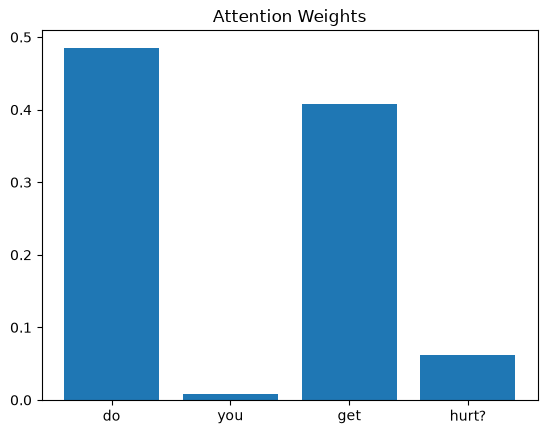

In [6]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

Question: 'Who built you?'                                   highest attention -> 'built' (0.585)   [true answer_id=3, predicted=3]
Question: 'Do you have a name?'                              highest attention -> 'name' (0.920)   [true answer_id=8, predicted=2]
Question: 'How do you feel about artificial intelligence?'   highest attention -> 'about' (0.899)   [true answer_id=9, predicted=2]


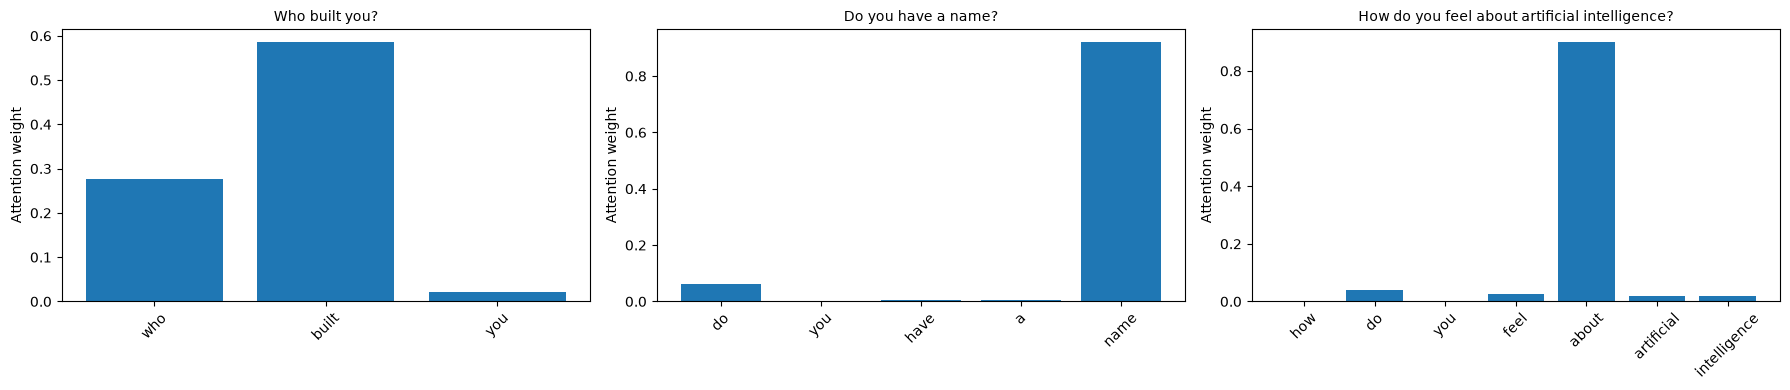

In [7]:
# Helper: words of a question (as the tokenizer sees them) + the attention weight of each word
def get_attention(question_text):
    q = question_text.lower()
    idx = df.index[df["question"] == q][0]                       # row of this question in the dataset
    tokens = tokenizer.texts_to_sequences([q])[0]
    words = [tokenizer.index_word[t] for t in tokens]            # aligned with the model's input
    with torch.no_grad():
        prediction, weights = model(X[idx:idx + 1])
    return words, weights[0, :len(words)].tolist(), prediction.argmax(1).item(), df["answer_id"][idx]

# Select three questions from three different answer groups
three_questions = ["Who built you?", "Do you have a name?", "How do you feel about artificial intelligence?"]

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, q in zip(axes, three_questions):
    words, att, predicted, true_id = get_attention(q)
    ax.bar(words, att)
    ax.set_title(q, fontsize=10)
    ax.set_ylabel("Attention weight")
    ax.tick_params(axis="x", rotation=45)

    top = words[att.index(max(att))]
    print(f"Question: {q!r:50} highest attention -> {top!r} ({max(att):.3f})   "
          f"[true answer_id={true_id}, predicted={predicted}]")

plt.tight_layout()
plt.show()


**Task 1 - observations**

| Question | Highest-attention word | Weight |
|---|---|---|
| who built you? | *built* | 0.585 |
| do you have a name? | *name* | 0.920 |
| how do you feel about artificial intelligence? | *about* | 0.899 |

**Do the highest-weighted words look important?** Partly. For the first two questions the model puts most of its attention on the word that carries the topic (*built*, *name*), which is what we would hope for. For the third question it focuses on *about*, a filler word, and gives almost nothing to *artificial* or *intelligence*, so here the attention is not on what a person would call the important words.

Two cautions when reading these charts: (1) this small model is weak. After 50 epochs the training loss is still about 2.0 and it classifies only about 30-38% of the questions correctly (two of the three predictions above are wrong), so its attention reflects what it learned to use, not true understanding. (2) Attention weights show where the model looked, not proof that those words are the reason for its answer.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

'How old are you?'     words=['how', 'old', 'are', 'you']
                       weights=[0.007, 0.025, 0.67, 0.052]
                       highest attention -> 'are'   [true answer_id=1, predicted=3]

"What's your age?"     words=["what's", 'your', 'age']
                       weights=[0.109, 0.005, 0.834]
                       highest attention -> 'age'   [true answer_id=1, predicted=10]



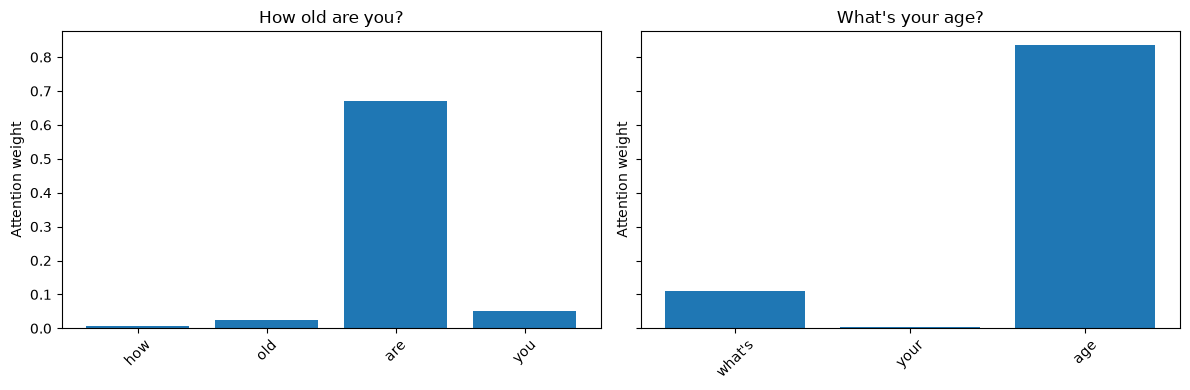

In [8]:
# Two questions with the same meaning (both ask about the age; both have answer_id = 1) but different wording
q_a = "How old are you?"
q_b = "What's your age?"

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
results = {}
for ax, q in zip(axes, [q_a, q_b]):
    words, att, predicted, true_id = get_attention(q)
    results[q] = (words, att)
    ax.bar(words, att)
    ax.set_title(q)
    ax.set_ylabel("Attention weight")
    ax.tick_params(axis="x", rotation=45)
    top = words[att.index(max(att))]
    print(f"{q!r:22} words={words}")
    print(f"{'':22} weights={[round(a, 3) for a in att]}")
    print(f"{'':22} highest attention -> {top!r}   [true answer_id={true_id}, predicted={predicted}]\n")

plt.tight_layout()
plt.show()


**Task 2 - observations**

The two questions both ask about age (true `answer_id = 1`) but are worded differently:

| Question | Highest-attention word | Weights |
|---|---|---|
| how old are you? | *are* (0.670) | how 0.007, old 0.025, are 0.670, you 0.052 |
| what's your age? | *age* (0.834) | what's 0.109, your 0.005, age 0.834 |

**Does the model focus on similar or different words?** Different words. For *What's your age?* it focuses on *age*, the topic word, but for *How old are you?* it focuses on *are* and gives *old* almost nothing. The model also predicts different answers for the two questions (3 and 10), and neither is the correct answer 1.

**What this suggests:** attention is a learned weighting over the input words, so it follows whatever the model found useful for its training labels, not the meaning of the sentence. *old* and *age* are different tokens with separate embeddings, and with only 14 examples per answer a small model has little chance to learn that they mean the same thing. Two questions with the same meaning can therefore get quite different attention patterns, especially when the model is weak. A bigger dataset or pretrained embeddings would be needed for similar meanings to give similar attention.